# Entrega 4: clasificación e integración

**TP Integrador de Aprendizaje Automático**

Proyecto: rendimiento de cultivos por partido en la Provincia de Buenos Aires.

Objetivo: anticipar una **campaña mala** (`mala85 = 1`, ratio real menor a 0,85) con un clasificador directo y compararlo con la alerta que se obtiene al aplicar el umbral sobre la regresión de la Entrega 3.

Protocolo (el mismo de la Entrega 3):

1. Se entrena cada configuración con **train** (1981/82 a 2013/14) y se mide en **validación** (2014/15 a 2018/19).
2. El **umbral de decisión** sobre la probabilidad estimada es un hiperparámetro más y se elige también en validación.
3. Se elige la mejor configuración de cada familia por el **costo total en validación** (FN = 2, FP = 1). El test no interviene.
4. Las configuraciones elegidas se reentrenan con **train + validación** y se evalúan **una sola vez en test** (2019/20 a 2024/25).

Modelos comparados: `DummyClassifier`, `DecisionTreeClassifier`, `KNeighborsClassifier` con `StandardScaler` dentro del Pipeline y `GaussianNB`, cada uno con y sin variables climáticas.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

ROOT = Path.cwd()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

from src.config import COST_FN, COST_FP, FIGURAS_DIR, THRESHOLD
from src.clasificacion import MODEL_LABELS, TARGET_CLF, UMBRAL_TEORICO, UMBRALES, run

# src.baselines fija el backend Agg para correr por consola; en el notebook se
# vuelve al backend inline para que las figuras se vean.
%matplotlib inline

COLOR_MODELO = {
    "dummy": "#b5b4ae",
    "regresion": "#6b6a65",
    "arbol": "#eb6834",
    "knn": "#2a78d6",
    "nb": "#1baf7a",
    "combinada": "#8f5bd6",
}
TINTA_SECUNDARIA = "#52514e"

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Búsqueda con validación

`run()` ejecuta todo el protocolo: la búsqueda, la selección, el reentrenamiento, la evaluación en test, el análisis de errores y el guardado del clasificador. Cada configuración se entrena una vez y se mide con 19 umbrales (0,05 a 0,95).

In [2]:
res = run(verbose=False)
busqueda = res["busqueda"]
elegidos = res["elegidos"]
test = res["test"]
print("Configuraciones de modelo:", busqueda[busqueda["familia"] != "dummy"].groupby(["familia", "variables", "params"]).ngroups)
print("Filas evaluadas (configuración × umbral):", len(busqueda))
print(f"Costo del Dummy en validación: {res['costo_dummy_val']:.0f} (no alerta nunca: {int(res['val'][TARGET_CLF].sum())} campañas malas × {COST_FN:.0f})")
display(
    elegidos[["modelo", "variables", "params", "umbral", "recall_val", "precision_val", "f1_val", "costo_val"]]
    .round(3)
)

Configuraciones de modelo: 268
Filas evaluadas (configuración × umbral): 5093
Costo del Dummy en validación: 540 (no alerta nunca: 270 campañas malas × 2)


,modelo,variables,params,umbral,recall_val,precision_val,f1_val,costo_val
0,DecisionTreeClassifier,con_clima,"max_depth=5, min_samples_leaf=50, class_weight...",0.65,0.248,0.644,0.358,443.0
1,KNeighborsClassifier,con_clima,"n_neighbors=500, weights=distance",0.40,0.026,0.583,0.050,531.0
2,GaussianNB,con_clima,var_smoothing=0.3,0.50,0.041,0.393,0.074,535.0
3,KNeighborsClassifier,sin_clima,"n_neighbors=150, weights=uniform",0.40,0.011,0.750,0.022,535.0
4,GaussianNB,sin_clima,var_smoothing=0.001,0.60,0.037,0.357,0.067,538.0
5,DecisionTreeClassifier,sin_clima,"max_depth=2, min_samples_leaf=1, class_weight=...",0.90,0.000,0.000,0.000,540.0


Sin clima, ningún modelo supera de forma apreciable al Dummy: el mejor árbol sin clima solo empata su costo (540) con un umbral que casi nunca alerta. Con clima, el **árbol** es el único que se separa con claridad del piso (443 contra 540). KNN y GaussianNB quedan apenas por debajo del Dummy en validación.

### 1.1 Umbral de decisión

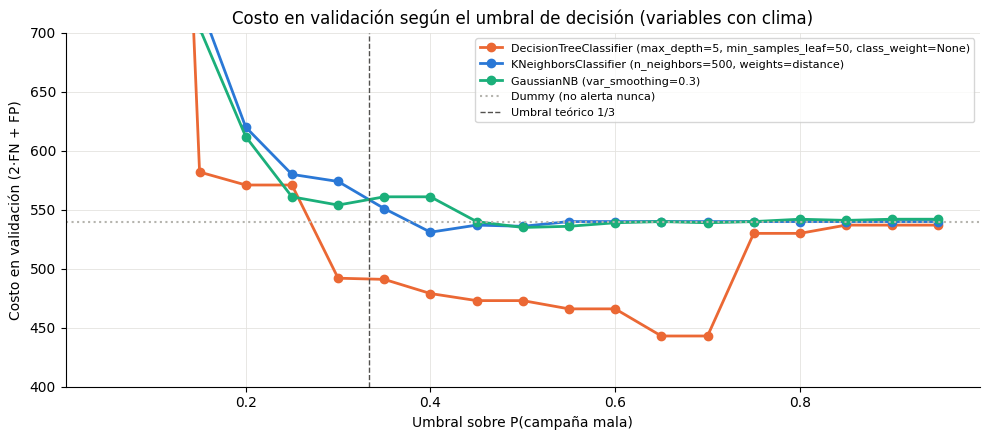

,umbral,recall_val,precision_val,costo_val
3231,0.05,1.000,0.148,1558.0
3232,0.10,0.956,0.148,1514.0
3233,0.15,0.419,0.297,582.0
3234,0.20,0.411,0.305,571.0
3235,0.25,0.411,0.305,571.0
3236,0.30,0.274,0.425,492.0
3237,0.35,0.274,0.428,491.0
3238,0.40,0.274,0.460,479.0
3239,0.45,0.270,0.480,473.0
3240,0.50,0.270,0.480,473.0


In [3]:
mejores = {}
for familia in ["arbol", "knn", "nb"]:
    fila = elegidos[(elegidos["familia"] == familia) & (elegidos["variables"] == "con_clima")].iloc[0]
    curva = busqueda[(busqueda["familia"] == familia) & (busqueda["variables"] == "con_clima") & (busqueda["params"] == fila["params"])]
    mejores[familia] = curva.sort_values("umbral")

fig, ax = plt.subplots(figsize=(10, 4.5))
for familia, curva in mejores.items():
    ax.plot(curva["umbral"], curva["costo_val"], marker="o", color=COLOR_MODELO[familia], linewidth=2,
            label=f"{MODEL_LABELS[familia]} ({curva['params'].iloc[0]})")
ax.axhline(res["costo_dummy_val"], color=COLOR_MODELO["dummy"], linestyle=":", linewidth=1.5, label="Dummy (no alerta nunca)")
ax.axvline(UMBRAL_TEORICO, color=TINTA_SECUNDARIA, linestyle="--", linewidth=1, label="Umbral teórico 1/3")
ax.set_ylim(400, 700)
ax.set_xlabel("Umbral sobre P(campaña mala)")
ax.set_ylabel("Costo en validación (2·FN + FP)")
ax.set_title("Costo en validación según el umbral de decisión (variables con clima)")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "clasificacion_umbral_costo.png", dpi=150)
plt.show()

display(mejores["arbol"][["umbral", "recall_val", "precision_val", "costo_val"]].round(3))

Con probabilidades bien calibradas, el umbral que minimiza el costo esperado es `COST_FP / (COST_FP + COST_FN) = 1/3`. El árbol elegido tiene su mínimo en 0,65 a 0,70: sus probabilidades no están calibradas y el período de validación tuvo menos campañas malas (14,8%) que el de entrenamiento. Con el umbral por defecto (0,5) el mismo árbol cuesta 473, también muy por debajo del Dummy. El salto entre 0,70 y 0,75 indica que el umbral elegido está en el borde de una meseta: un umbral algo menor es más robusto que uno mayor.

### 1.2 Peso de las clases en el árbol

In [4]:
arbol = busqueda[(busqueda["familia"] == "arbol") & (busqueda["variables"] == "con_clima")].copy()
arbol["class_weight"] = arbol["class_weight"].fillna("None")
display(pd.DataFrame({
    "mejor costo (umbral 0,5)": arbol[arbol["umbral"] == 0.5].groupby("class_weight")["costo_val"].min(),
    "mejor costo (umbral elegido)": arbol.groupby("class_weight")["costo_val"].min(),
}))

,"mejor costo (umbral 0,5)",mejor costo (umbral elegido)
class_weight,,
None,465.0,443.0
balanced,564.0,474.0


`class_weight="balanced"` no hace falta cuando el umbral se ajusta: el balanceo y el umbral son dos formas de mover la misma frontera. Sin balanceo y con el umbral por defecto, el árbol ya supera al Dummy (465 contra 540).

## 2. Tabla comparativa en test

In [5]:
comparacion = res["comparacion"]
display(
    comparacion[["modelo", "params", "umbral", "costo_val", "accuracy", "precision", "recall", "f1", "costo", "tp", "fp", "fn", "tn", "tasa_alertas"]]
    .round(3)
)
print("Campañas malas reales en test:", int(test[TARGET_CLF].sum()), f"({test[TARGET_CLF].mean():.1%})")

,modelo,params,umbral,costo_val,accuracy,precision,recall,f1,costo,tp,fp,fn,tn,tasa_alertas
0,Dummy (clase mayoritaria),-,NaN,540.0,0.787,0.000,0.000,0.000,940.0,0,0,470,1734,0.000
1,Regresión + umbral (Entrega 3),"KNN k=300, distance",0.85,NaN,0.821,0.770,0.228,0.351,758.0,107,32,363,1702,0.063
2,DecisionTreeClassifier (con_clima),"max_depth=5, min_samples_leaf=50, class_weight...",0.65,443.0,0.823,0.650,0.368,0.470,687.0,173,93,297,1641,0.121
3,KNeighborsClassifier (con_clima),"n_neighbors=500, weights=distance",0.40,531.0,0.800,0.603,0.187,0.286,822.0,88,58,382,1676,0.066
4,GaussianNB (con_clima),var_smoothing=0.3,0.50,535.0,0.822,0.618,0.428,0.506,662.0,201,124,269,1610,0.147
5,KNeighborsClassifier (sin_clima),"n_neighbors=150, weights=uniform",0.40,535.0,0.787,0.000,0.000,0.000,940.0,0,0,470,1734,0.000
6,GaussianNB (sin_clima),var_smoothing=0.001,0.60,538.0,0.785,0.421,0.017,0.033,935.0,8,11,462,1723,0.009
7,DecisionTreeClassifier (sin_clima),"max_depth=2, min_samples_leaf=1, class_weight=...",0.90,540.0,0.787,0.500,0.004,0.008,938.0,2,2,468,1732,0.002
8,Clasificador o regresión (alerta combinada),OR,NaN,NaN,0.816,0.612,0.379,0.468,697.0,178,113,292,1621,0.132


Campañas malas reales en test: 470 (21.3%)


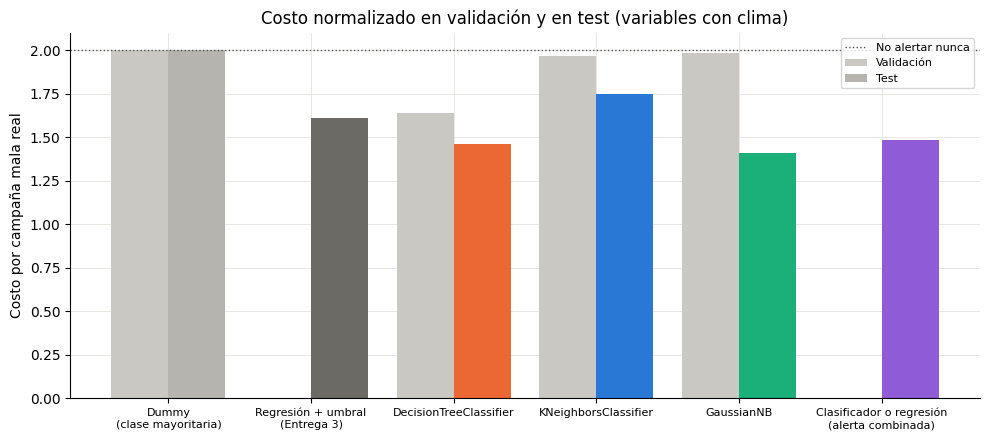

In [6]:
sistemas = comparacion[comparacion["variables"].isin(["-", "con_clima"])].copy()
positivos_val = res["val"][TARGET_CLF].sum()
sistemas["costo_por_pos_val"] = sistemas["costo_val"] / positivos_val

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(sistemas))
ax.bar(x - 0.2, sistemas["costo_por_pos_val"], width=0.4, color="#c9c8c2", label="Validación")
ax.bar(x + 0.2, sistemas["costo_por_pos"], width=0.4, color=[COLOR_MODELO[f] for f in sistemas["familia"]], label="Test")
ax.axhline(COST_FN, color=TINTA_SECUNDARIA, linestyle=":", linewidth=1, label="No alertar nunca")
ax.set_xticks(x, [m.replace(" (con_clima)", "").replace(" (", "\n(") for m in sistemas["modelo"]], fontsize=8)
ax.set_ylabel("Costo por campaña mala real")
ax.set_title("Costo normalizado en validación y en test (variables con clima)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "clasificacion_costo_val_test.png", dpi=150)
plt.show()

El costo se divide por la cantidad de campañas malas reales de cada período para poder comparar validación (270) y test (470). La regresión y la alerta combinada no tienen costo de validación: el regresor final se entrenó con train + validación.

## 3. Matrices de confusión

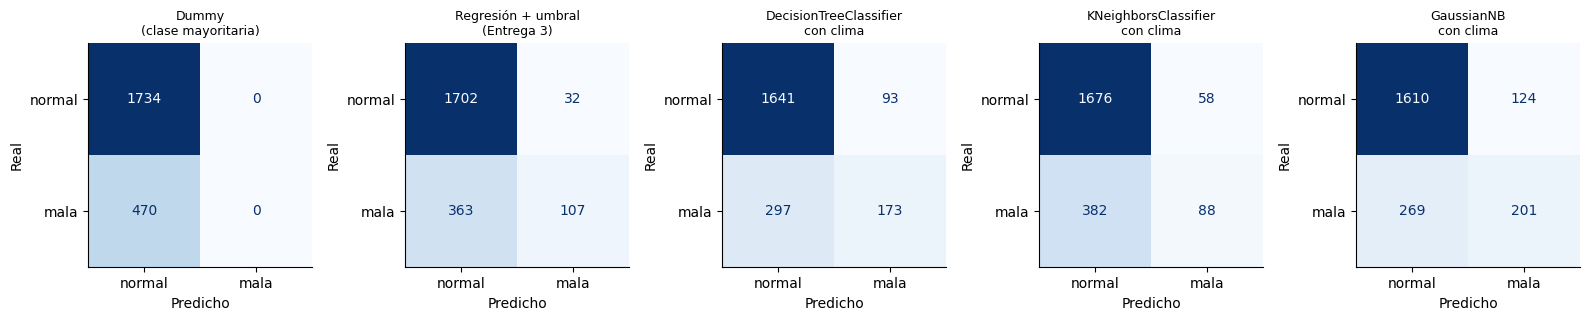

In [7]:
mostrar = [
    MODEL_LABELS["dummy"],
    MODEL_LABELS["regresion"],
    "DecisionTreeClassifier (con_clima)",
    "KNeighborsClassifier (con_clima)",
    "GaussianNB (con_clima)",
]
preds = dict(res["preds_test"])
y_test = test[TARGET_CLF].to_numpy()

fig, axes = plt.subplots(1, len(mostrar), figsize=(16, 3.6))
for ax, nombre in zip(axes, mostrar):
    cm = confusion_matrix(y_test, preds[nombre], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["normal", "mala"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(nombre.replace(" (con_clima)", "\ncon clima").replace(" (", "\n("), fontsize=9)
    ax.grid(False)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "clasificacion_matrices_confusion.png", dpi=150)
plt.show()

## 4. Análisis de falsos positivos y falsos negativos

### 4.1 Según el ratio real

,modelo,banda_ratio,n,alertas,fn,fp,tasa_alerta
0,DecisionTreeClassifier (con_clima),"< 0,50",84,57,27,0,0.678571
1,DecisionTreeClassifier (con_clima),"0,50-0,75",217,98,119,0,0.451613
2,DecisionTreeClassifier (con_clima),"0,75-0,85",169,18,151,0,0.106509
3,DecisionTreeClassifier (con_clima),"0,85-0,95",452,22,0,22,0.048673
4,DecisionTreeClassifier (con_clima),"0,95-1,05",556,36,0,36,0.064748
5,DecisionTreeClassifier (con_clima),">= 1,05",726,35,0,35,0.048209
6,Regresión + umbral (Entrega 3),"< 0,50",84,27,57,0,0.321429
7,Regresión + umbral (Entrega 3),"0,50-0,75",217,78,139,0,0.359447
8,Regresión + umbral (Entrega 3),"0,75-0,85",169,2,167,0,0.011834
9,Regresión + umbral (Entrega 3),"0,85-0,95",452,6,0,6,0.013274


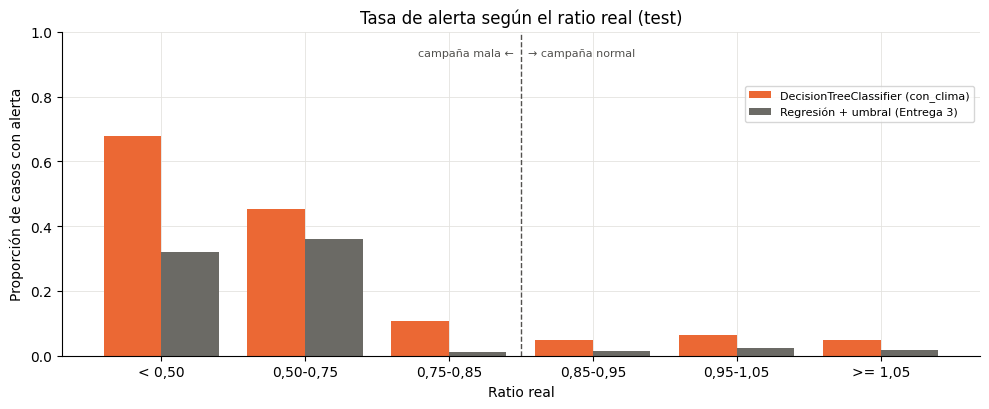

In [8]:
por_ratio = res["errores_por_ratio"]
display(por_ratio)

fig, ax = plt.subplots(figsize=(10, 4.2))
bandas = por_ratio["banda_ratio"].unique()
x = np.arange(len(bandas))
for i, (nombre, g) in enumerate(por_ratio.groupby("modelo", sort=False)):
    familia = "arbol" if "Tree" in nombre else "regresion"
    ax.bar(x + (i - 0.5) * 0.4, g["tasa_alerta"], width=0.4, color=COLOR_MODELO[familia], label=nombre)
ax.axvline(2.5, color=TINTA_SECUNDARIA, linestyle="--", linewidth=1)
ax.text(2.45, 0.95, "campaña mala ←", ha="right", va="top", fontsize=8, color=TINTA_SECUNDARIA)
ax.text(2.55, 0.95, "→ campaña normal", ha="left", va="top", fontsize=8, color=TINTA_SECUNDARIA)
ax.set_xticks(x, bandas)
ax.set_ylim(0, 1)
ax.set_xlabel("Ratio real")
ax.set_ylabel("Proporción de casos con alerta")
ax.set_title("Tasa de alerta según el ratio real (test)")
ax.legend(fontsize=8, loc="upper right", bbox_to_anchor=(1, 0.85))
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "clasificacion_errores_por_ratio.png", dpi=150)
plt.show()

A la izquierda de la línea, las barras son el recall de cada banda; a la derecha, la tasa de falsas alarmas.

- **Falsos negativos:** la mitad de los FN del árbol (151 de 297) son campañas apenas malas, con ratio entre 0,75 y 0,85. En las campañas muy malas (ratio < 0,50) el árbol detecta el 68% y la regresión, el 32%.
- **Falsos positivos:** la tasa de falsas alarmas es baja y pareja (5% a 6%) en todas las bandas normales. Solo 22 de 93 FP son campañas "casi malas" (0,85 a 0,95), por lo que los FP no se explican por cercanía al umbral.

### 4.2 Perfil de cada tipo de error

In [9]:
display(res["perfil_errores"].round(3))

,modelo,tipo,n,ratio_mediana,prev5_ceros_media,clima_precip_total_mm_media,clima_sequia_max_dias_media,clima_dias_tmax_30_media,share_2022
0,DecisionTreeClassifier (con_clima),FN,297,0.756,0.061,305.543,20.761,36.808,0.249
1,DecisionTreeClassifier (con_clima),FP,93,1.009,0.011,256.541,24.140,40.989,0.118
2,DecisionTreeClassifier (con_clima),VN,1641,1.025,0.010,374.856,18.620,38.812,0.081
3,DecisionTreeClassifier (con_clima),VP,173,0.561,0.012,210.453,23.630,61.514,0.855
4,Regresión + umbral (Entrega 3),FN,363,0.738,0.055,282.964,23.105,34.592,0.317
5,Regresión + umbral (Entrega 3),FP,32,1.019,0.000,269.597,18.875,69.000,0.312
6,Regresión + umbral (Entrega 3),VN,1702,1.024,0.010,370.370,18.917,38.364,0.079
7,Regresión + umbral (Entrega 3),VP,107,0.574,0.000,228.401,17.449,84.271,1.000


- Los **VP** se concentran en la sequía 2022/23 (85% de los VP del árbol): poca lluvia (210 mm de media) y muchos días con más de 30 °C (62).
- Los **FN** tienen lluvia cercana a la de las campañas normales (306 mm contra 375 mm) y pocos días de calor (37): son campañas malas por poco margen o por causas que las variables de la ventana no registran (por ejemplo, granizo, plagas o excesos de agua puntuales).
- Los **FP** son campañas secas (257 mm, la sequía máxima más larga: 24 días) que terminaron bien. El clima de la ventana anticipaba una campaña mala, pero el cultivo la compensó o la lluvia llegó a tiempo después del corte.

### 4.3 Por cultivo y por campaña

recall                                                         precision                                                             costo  \
modelo      DecisionTreeClassifier (con_clima) Regresión + umbral (Entrega 3) DecisionTreeClassifier (con_clima) Regresión + umbral (Entrega 3) DecisionTreeClassifier (con_clima)   
cultivo                                                                                                                                                                              
Girasol                                  0.051                          0.000                              1.000                          0.000                               74.0   
Maíz                                     0.434                          0.371                              0.633                          0.671                              198.0   
Soja total                               0.423                          0.362                              0.778                          0.900                              190.0   
Trigo total                              0.331                          0.000                              0.541                          0.000                              225.0   

                                            
modelo      Regresión + umbral (Entrega 3)  
cultivo                                     
Girasol                               78.0  
Maíz                                 206.0  
Soja total                           196.0  
Trigo total                          278.0

positivos_reales                                                            recall                                                                fp  \
modelo          DecisionTreeClassifier (con_clima) Regresión + umbral (Entrega 3) DecisionTreeClassifier (con_clima) Regresión + umbral (Entrega 3) DecisionTreeClassifier (con_clima)   
campania_inicio                                                                                                                                                                          
2019                                          58.0                           58.0                              0.121                          0.000                                9.0   
2020                                          70.0                           70.0                              0.129                          0.000                                6.0   
2021                                          73.0                           73.0                              0.055                          0.000                               12.0   
2022                                         222.0                          222.0                              0.667                          0.482                               11.0   
2023                                          34.0                           34.0                              0.147                          0.000                               10.0   
2024                                          13.0                           13.0                              0.000                          0.000                               45.0   

                                                                               fn                                 
modelo          Regresión + umbral (Entrega 3) DecisionTreeClassifier (con_clima) Regresión + umbral (Entrega 3)  
campania_inicio                                                                                                   
2019                                       0.0                               51.0                           58.0  
2020                                       0.0                               61.0                           70.0  
2021                                       0.0                               69.0                           73.0  
2022                                      10.0                               74.0                          115.0  
2023                                       2.0                               29.0                           34.0  
2024                                      20.0                               13.0                           13.0

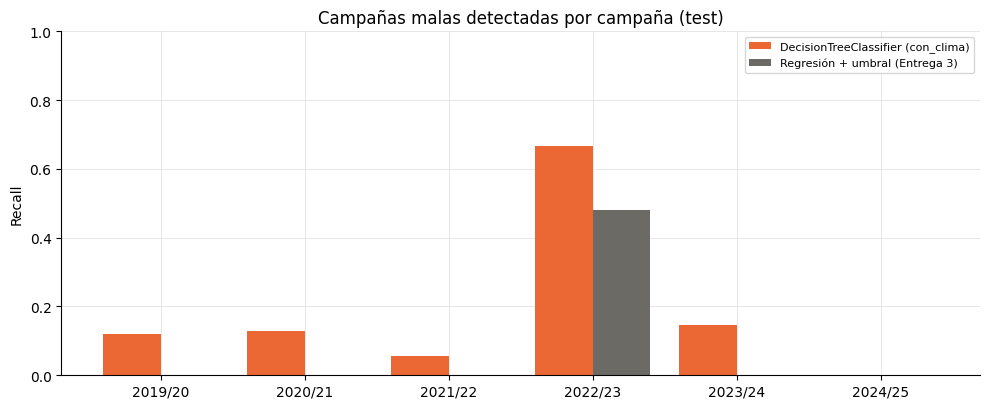

In [10]:
sel = res["seleccionado"]
clave = [sel, MODEL_LABELS["regresion"]]
por_cultivo = res["por_cultivo"]
display(por_cultivo[por_cultivo["modelo"].isin(clave)].pivot(index="cultivo", columns="modelo", values=["recall", "precision", "costo"]).round(3))
por_campania = res["por_campania"]
pc = por_campania[por_campania["modelo"].isin(clave)]
display(pc.pivot(index="campania_inicio", columns="modelo", values=["positivos_reales", "recall", "fp", "fn"]).round(3))

fig, ax = plt.subplots(figsize=(10, 4.2))
anios = sorted(pc["campania_inicio"].unique())
x = np.arange(len(anios))
for i, nombre in enumerate(clave):
    g = pc[pc["modelo"] == nombre].set_index("campania_inicio").loc[anios]
    familia = "arbol" if nombre == sel else "regresion"
    ax.bar(x + (i - 0.5) * 0.4, g["recall"], width=0.4, color=COLOR_MODELO[familia], label=nombre)
ax.set_xticks(x, [f"{a}/{str(a + 1)[-2:]}" for a in anios])
ax.set_ylim(0, 1)
ax.set_ylabel("Recall")
ax.set_title("Campañas malas detectadas por campaña (test)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "clasificacion_recall_por_campania.png", dpi=150)
plt.show()

- La regresión solo detecta campañas malas en 2022/23: fuera de la sequía, su recall es 0. El árbol detecta entre el 5% y el 15% en 2019/20 a 2021/22 y en 2023/24, ninguna en 2024/25 y el 67% en 2022/23.
- En **trigo y girasol** la regresión no emite ninguna alerta. El árbol recupera el 33% de las campañas malas de trigo; en girasol sigue casi ciego (2 de 39).
- En 2024/25 el árbol emite 45 falsas alarmas y ningún acierto: es el año con más FP.

### 4.4 Acuerdo entre los dos sistemas

In [11]:
display(res["acuerdo"].round(3))

,clasificador,regresion,n,malas_reales,precision
0,alerta,alerta,114,102,0.895
1,alerta,normal,152,71,0.467
2,normal,alerta,25,5,0.200
3,normal,normal,1913,292,0.153


Cuando ambos sistemas alertan, 9 de cada 10 alertas son campañas malas reales. Cuando solo alerta la regresión, la precisión cae al 20%, casi la tasa base. Por eso la app usa el clasificador como alerta principal y la coincidencia con la regresión como señal de alta confianza, en lugar de alertar cuando cualquiera de los dos alerta.

## 5. Reproducibilidad

```bash
python -m src.clasificacion
python -m jupyter nbconvert --to notebook --execute --inplace notebooks/04_clasificacion.ipynb
```

`src.clasificacion` guarda las tablas en `datos/procesado/clasificacion_*.csv` y el clasificador en `modelos/`. Este notebook ejecuta el mismo protocolo y genera las figuras de `informe/figuras/clasificacion_*.png`.